# True vs decoy-based precision on simulated reads

For each layout (Dual barcodes, Greedy + 2-OPT, Zipcodes), 1,000,000 reads were simulated from the printed barcodes with the Press error model (high regime: 3% substitutions, 15% insertions, 14% deletions) and decoded with QUIK (4-mer strategy) against the **combined** whitelist of real barcodes plus decoys, at rejection thresholds $r \in \{5, 6, 7\}$. The header of every read carries the barcode it was simulated from, so the true precision of the combined decoding is known and can be compared with the decoy-based estimate.

Notation: $N$ = simulated reads, $A$ = reads assigned to any whitelist entry, $D$ = reads assigned to decoys, $R = A - D$ = reads assigned to real barcodes, $C$ = reads assigned to their true barcode, $F = R - C$ = reads assigned to a wrong real barcode, $\phi_{\text{global}} = n_D/(n_R + n_D)$.

* True precision: $C/A$ (the quantity estimated by the benchmark formula) and $C/R$ (reads on real barcodes only).
* Decoy-based precision: $\hat P = 1 - (D/A)/\phi_{\text{global}}$.
* Effective decoy share: $\phi_{\text{eff}} = D/(D+F)$, the fraction of misassigned reads that landed on decoys. $\hat P$ is unbiased when $\phi_{\text{eff}} = \phi_{\text{global}}$; using $\phi_{\text{eff}}$ instead of $\phi_{\text{global}}$ reproduces $C/A$ exactly.

All three layouts used a 1:2 decoy-to-real ratio ($\phi_{\text{global}} = 1/3$).

In [ ]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})

DATA = Path("../../data")
WHITELIST_DIR = DATA / "1in1"
QUIK_DIR = DATA / "quik_out_manuscript"
OUT_DIR = Path(".")
THRESHOLDS = [5, 6, 7]
SEG = 18

LAYOUTS = {
    "Dual barcodes": {"key": "dual", "whitelist": "layout_235x363_dual_4x4.txt"},
    "Greedy + 2-OPT": {"key": "greedy", "whitelist": "layout_235x363_randombarcodes_opt.txt"},
    "Zipcodes": {"key": "zipV2", "whitelist": "layout_235x363_zipcodes_nosep.txt"},
}


def run_prefix(key, r):
    return QUIK_DIR / f"simreads_thr{r}_1M" / f"quik_{key}_combined_1M"

## Readers

QUIK writes one FASTQ record per assigned read, with the header `@read_<n>_barcode_<true index>_calledidx_<called index>_<called sequence>`. The true index is the 0-based line of the printed layout file from which the read was simulated. The called index refers to the combined whitelist, in which the real barcodes are not necessarily in layout order, so assignments are compared by **sequence**.

In [2]:
HEADER = re.compile(r"^@read_(\d+)_barcode_(\d+)_calledidx_(\d+)_([ACGTN]+)\s*$")


def read_whitelist(path):
    with open(path) as handle:
        return [line.strip().upper() for line in handle if line.strip()]


def read_assignments(path):
    true_idx, called_seq = [], []
    with open(path) as handle:
        for i, line in enumerate(handle):
            if i % 4:
                continue
            match = HEADER.match(line)
            if match is None:
                raise ValueError(f"Unexpected header in {path}: {line!r}")
            true_idx.append(int(match[2]))
            called_seq.append(match[4])
    return pd.DataFrame({"true_idx": true_idx, "called_seq": called_seq})


def read_calling_stats(path):
    text = Path(path).read_text()
    return {
        "whitelist_file": re.search(r"Reading barcodes from: (\S+)", text)[1],
        "whitelist_size": int(re.search(r"Loaded (\d+) barcodes", text)[1]),
        "total_reads": int(re.search(r"Total reads: (\d+)", text)[1]),
        "assigned_reads": int(re.search(r"Assigned reads: (\d+)", text)[1]),
        "threshold": int(re.search(r"Rejection threshold: (\d+)", text)[1]),
        "strategy": re.search(r"Strategy: (\S+)", text)[1],
    }

## Available runs

In [3]:
runs = []
for name, cfg in LAYOUTS.items():
    for r in THRESHOLDS:
        stats_path = Path(f"{run_prefix(cfg['key'], r)}_barcode_calling_stats.txt")
        row = {"layout": name, "threshold": r, "available": stats_path.exists()}
        if stats_path.exists():
            st = read_calling_stats(stats_path)
            assert st["threshold"] == r
            row.update(st)
        runs.append(row)
runs = pd.DataFrame(runs).set_index(["layout", "threshold"])
runs

available                         whitelist_file  \
layout         threshold                                                     
Dual barcodes  5               True    dual_whitelist_real_plus_decoys.txt   
               6               True    dual_whitelist_real_plus_decoys.txt   
               7               True    dual_whitelist_real_plus_decoys.txt   
Greedy + 2-OPT 5               True  greedy_whitelist_real_plus_decoys.txt   
               6               True  greedy_whitelist_real_plus_decoys.txt   
               7               True  greedy_whitelist_real_plus_decoys.txt   
Zipcodes       5               True     zip_whitelist_real_plus_decoys.txt   
               6               True     zip_whitelist_real_plus_decoys.txt   
               7               True     zip_whitelist_real_plus_decoys.txt   

                          whitelist_size  total_reads  assigned_reads  \
layout         threshold                                                
Dual barcodes  5                  127957      1000000          126596   
               6                  127957      1000000          264016   
               7                  127957      1000000          447907   
Greedy + 2-OPT 5                  127957      1000000          125485   
               6                  127957      1000000          260692   
               7                  127957      1000000          440813   
Zipcodes       5                  128107      1000000          140302   
               6                  128107      1000000          295061   
               7                  128107      1000000          501102   

                              strategy  
layout         threshold                
Dual barcodes  5          4_mer_gpu_v4  
               6          4_mer_gpu_v4  
               7          4_mer_gpu_v4  
Greedy + 2-OPT 5          4_mer_gpu_v4  
               6          4_mer_gpu_v4  
               7          4_mer_gpu_v4  
Zipcodes       5          4_mer_gpu_v4  
               6          4_mer_gpu_v4  
               7          4_mer_gpu_v4

## True and decoy-based precision

In [4]:
results, assignments = [], {}
for name, cfg in LAYOUTS.items():
    real = np.array(read_whitelist(WHITELIST_DIR / cfg["whitelist"]))
    real_set = set(real)
    for r in THRESHOLDS:
        if not runs.loc[(name, r), "available"]:
            continue
        st = runs.loc[(name, r)]
        comb = read_assignments(f"{run_prefix(cfg['key'], r)}_R1_filtered.fastq")
        assert len(comb) == st.assigned_reads
        comb["true_seq"] = real[comb.true_idx.values]
        comb["is_decoy"] = ~comb.called_seq.isin(real_set)
        comb["correct"] = comb.called_seq == comb.true_seq
        assignments[(name, r)] = comb

        N = int(st.total_reads)
        n_decoy = int(st.whitelist_size) - len(real)
        phi = n_decoy / int(st.whitelist_size)
        A, D = len(comb), int(comb.is_decoy.sum())
        R, C = A - D, int(comb.correct.sum())
        F = R - C
        results.append({
            "layout": name, "threshold": r, "reads": N, "n_real": len(real), "n_decoy": n_decoy,
            "phi_global": phi, "assigned_any": A, "assigned_to_decoys": D,
            "assigned_to_wrong_real": F, "assigned_correct": C,
            "assignment_rate_real": R / N, "recall_true": C / N,
            "true_precision": C / A, "true_precision_real": C / R,
            "decoy_precision": 1 - (D / A) / phi,
            "phi_eff": D / (D + F) if D + F else np.nan,
        })
results = pd.DataFrame(results).set_index(["layout", "threshold"])
results["phi_eff_over_phi"] = results.phi_eff / results.phi_global
results["decoy_minus_true"] = results.decoy_precision - results.true_precision
results.to_csv(OUT_DIR / "precision_calibration_1M.csv")
results

reads  n_real  n_decoy  phi_global  assigned_any  \
layout         threshold                                                       
Dual barcodes  5          1000000   85305    42652    0.333331        126596   
               6          1000000   85305    42652    0.333331        264016   
               7          1000000   85305    42652    0.333331        447907   
Greedy + 2-OPT 5          1000000   85305    42652    0.333331        125485   
               6          1000000   85305    42652    0.333331        260692   
               7          1000000   85305    42652    0.333331        440813   
Zipcodes       5          1000000   85305    42802    0.334111        140302   
               6          1000000   85305    42802    0.334111        295061   
               7          1000000   85305    42802    0.334111        501102   

                          assigned_to_decoys  assigned_to_wrong_real  \
layout         threshold                                               
Dual barcodes  5                         245                     494   
               6                        1324                    2508   
               7                        4617                    9109   
Greedy + 2-OPT 5                           1                       4   
               6                          28                      57   
               7                         489                     890   
Zipcodes       5                        1396                    5946   
               6                        5646                   24298   
               7                       15415                   65104   

                          assigned_correct  assignment_rate_real  recall_true  \
layout         threshold                                                        
Dual barcodes  5                    125857              0.126351     0.125857   
               6                    260184              0.262692     0.260184   
               7                    434181              0.443290     0.434181   
Greedy + 2-OPT 5                    125480              0.125484     0.125480   
               6                    260607              0.260664     0.260607   
               7                    439434              0.440324     0.439434   
Zipcodes       5                    132960              0.138906     0.132960   
               6                    265117              0.289415     0.265117   
               7                    420583              0.485687     0.420583   

                          true_precision  true_precision_real  \
layout         threshold                                        
Dual barcodes  5                0.994163             0.996090   
               6                0.985486             0.990453   
               7                0.969355             0.979451   
Greedy + 2-OPT 5                0.999960             0.999968   
               6                0.999674             0.999781   
               7                0.996872             0.997979   
Zipcodes       5                0.947670             0.957194   
               6                0.898516             0.916044   
               7                0.839316             0.865955   

                          decoy_precision   phi_eff  phi_eff_over_phi  \
layout         threshold                                                
Dual barcodes  5                 0.994194  0.331529          0.994595   
               6                 0.984955  0.345511          1.036543   
               7                 0.969076  0.336369          1.009115   
Greedy + 2-OPT 5                 0.999976  0.200000          0.600005   
               6                 0.999678  0.329412          0.988243   
               7                 0.996672  0.354605          1.063823   
Zipcodes       5                 0.970220  0.190139          0.569089   
               6                 0.942729  0.188552          0.564339   
               7

In [5]:
summary = pd.DataFrame({
    "Assignment rate (%)": results.assignment_rate_real * 100,
    "True recall (%)": results.recall_true * 100,
    "True precision (%)": results.true_precision * 100,
    "Decoy-based precision (%)": results.decoy_precision * 100,
    "Difference (pp)": results.decoy_minus_true * 100,
    "phi_global": results.phi_global,
    "phi_eff": results.phi_eff,
}).round(3)
summary.to_csv(OUT_DIR / "precision_calibration_1M_summary.csv")
summary

Assignment rate (%)  True recall (%)  \
layout         threshold                                         
Dual barcodes  5                       12.635           12.586   
               6                       26.269           26.018   
               7                       44.329           43.418   
Greedy + 2-OPT 5                       12.548           12.548   
               6                       26.066           26.061   
               7                       44.032           43.943   
Zipcodes       5                       13.891           13.296   
               6                       28.941           26.512   
               7                       48.569           42.058   

                          True precision (%)  Decoy-based precision (%)  \
layout         threshold                                                  
Dual barcodes  5                      99.416                     99.419   
               6                      98.549                     98.496   
               7                      96.936                     96.908   
Greedy + 2-OPT 5                      99.996                     99.998   
               6                      99.967                     99.968   
               7                      99.687                     99.667   
Zipcodes       5                      94.767                     97.022   
               6                      89.852                     94.273   
               7                      83.932                     90.793   

                          Difference (pp)  phi_global  phi_eff  
layout         threshold                                        
Dual barcodes  5                    0.003       0.333    0.332  
               6                   -0.053       0.333    0.346  
               7                   -0.028       0.333    0.336  
Greedy + 2-OPT 5                    0.002       0.333    0.200  
               6                    0.000       0.333    0.329  
               7                   -0.020       0.333    0.355  
Zipcodes       5                    2.255       0.334    0.190  
               6                    4.421       0.334    0.189  
               7                    6.861       0.334    0.191

## Where misassigned reads land

For every misassigned read, the called barcode is compared with the true barcode: does it share the first 18 nt (Dual: same block identifier; Zipcodes: same column code), the last 18 nt (Dual: same spot code; Zipcodes: same row code), or neither? The decoy share within each category shows whether the decoys capture local errors.

In [6]:
rows = []
for (name, r), comb in assignments.items():
    wrong = comb[~comb.correct]
    first = wrong.called_seq.str[:SEG] == wrong.true_seq.str[:SEG]
    last = wrong.called_seq.str[SEG:] == wrong.true_seq.str[SEG:]
    relation = np.select([first, last], ["shares first 18 nt", "shares last 18 nt"], "shares neither")
    target = np.where(wrong.is_decoy, "decoy", "real")
    counts = pd.crosstab([pd.Series(relation, name="relation")], pd.Series(target, name="target"))
    counts = counts.reindex(columns=["decoy", "real"], fill_value=0)
    counts.index = pd.MultiIndex.from_product([[name], [r], counts.index], names=["layout", "threshold", "relation"])
    rows.append(counts)
landing = pd.concat(rows)
landing["decoy_share"] = (landing.decoy / landing.sum(axis=1)).round(3)
landing.to_csv(OUT_DIR / "misassignment_landing_1M.csv")
landing

target                                       decoy   real  decoy_share
layout         threshold relation                                     
Dual barcodes  5         shares first 18 nt    240    490        0.329
                         shares last 18 nt       1      0        1.000
                         shares neither          4      4        0.500
               6         shares first 18 nt   1291   2442        0.346
                         shares last 18 nt       5      8        0.385
                         shares neither         28     58        0.326
               7         shares first 18 nt   4178   8183        0.338
                         shares last 18 nt      28     45        0.384
                         shares neither        411    881        0.318
Greedy + 2-OPT 5         shares neither          1      4        0.200
               6         shares neither         28     57        0.329
               7         shares neither        489    890        0.355
Zipcodes       5         shares first 18 nt   1283   5404        0.192
                         shares last 18 nt     113    539        0.173
                         shares neither          0      3        0.000
               6         shares first 18 nt   4975  21278        0.190
                         shares last 18 nt     661   2986        0.181
                         shares neither         10     34        0.227
               7         shares first 18 nt  12836  54316        0.191
                         shares last 18 nt    2447  10411        0.190
                         shares neither        132    377        0.259

## Figure

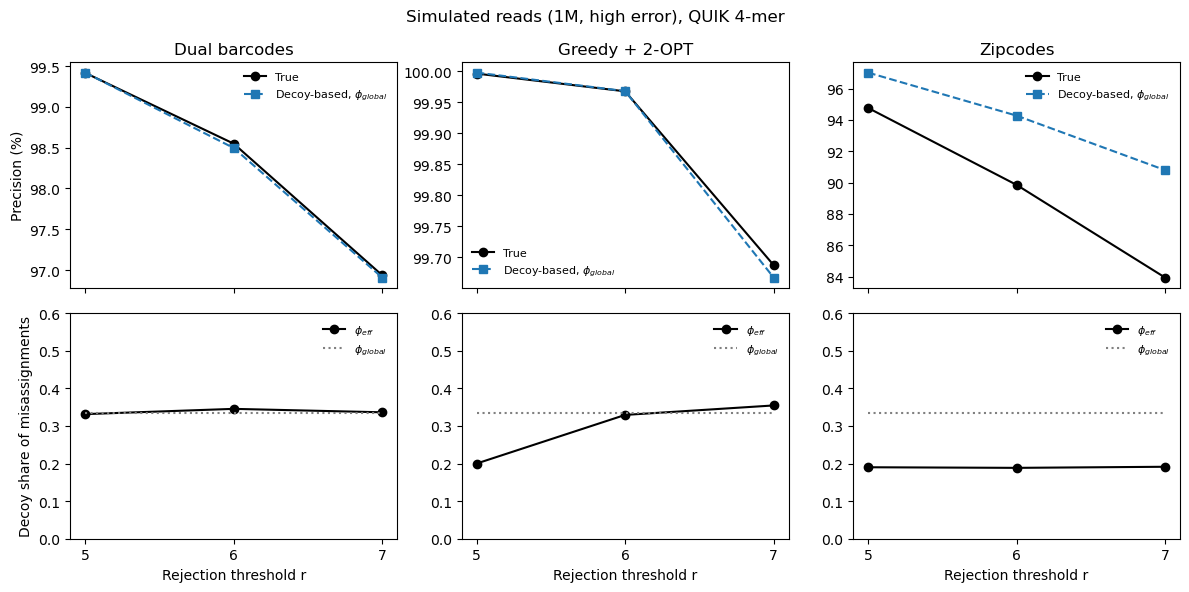

In [7]:
fig, axes = plt.subplots(2, len(LAYOUTS), figsize=(4 * len(LAYOUTS), 6), sharex=True)
for j, name in enumerate(LAYOUTS):
    df = results.loc[name]
    ax = axes[0, j]
    ax.plot(df.index, df.true_precision * 100, "o-", color="black", label="True")
    ax.plot(df.index, df.decoy_precision * 100, "s--", color="tab:blue", label=r"Decoy-based, $\phi_{global}$")
    ax.set_title(name)
    ax.set_ylabel("Precision (%)" if j == 0 else "")
    ax.legend(frameon=False, fontsize=8)
    ax = axes[1, j]
    ax.plot(df.index, df.phi_eff, "o-", color="black", label=r"$\phi_{eff}$")
    ax.plot(df.index, df.phi_global, ":", color="grey", label=r"$\phi_{global}$")
    ax.set_ylim(0, 0.6)
    ax.set_xlabel("Rejection threshold r")
    ax.set_ylabel("Decoy share of misassignments" if j == 0 else "")
    ax.set_xticks(THRESHOLDS)
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Simulated reads (1M, high error), QUIK 4-mer")
fig.tight_layout()
fig.savefig(OUT_DIR / "precision_calibration_1M.pdf")
plt.show()